<a href="https://colab.research.google.com/github/Vishali-Vivek006/Engineering-employability-prediction/blob/main/notebooks/04_modeltraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import pandas as pd
import joblib

from scipy import sparse

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [13]:

import os
import numpy as np

files_to_check = [
    "/content/X_train_processed.npz",
    "/content/X_test_processed.npz",
    "/content/X_train_processed.npy",
    "/content/X_test_processed.npy",
]

for path in files_to_check:
    if os.path.exists(path):
        print(f"\nFound: {os.path.basename(path)}")
        print("Size:", os.path.getsize(path), "bytes")

        try:
            data = np.load(path, allow_pickle=False)
            if isinstance(data, np.lib.npyio.NpzFile):
                print("Format: NPZ archive")
                print("Internal keys:", data.files)
                data.close()
            else:
                print("Format: NumPy array")
                print("Shape:", data.shape)
                print("Data type:", data.dtype)
        except Exception as e:
            print("NumPy inspection error:", repr(e))
    else:
        print(f"\nNot found: {os.path.basename(path)}")



Found: X_train_processed.npz
Size: 5408128 bytes
Format: NumPy array
Shape: (4000, 169)
Data type: float64

Found: X_test_processed.npz
Size: 1352128 bytes
Format: NumPy array
Shape: (1000, 169)
Data type: float64

Not found: X_train_processed.npy

Not found: X_test_processed.npy


In [14]:

import os
import numpy as np
import pandas as pd

# Load processed feature arrays
X_train = np.load("/content/X_train_processed.npz")
X_test = np.load("/content/X_test_processed.npz")

# Load target labels
y_train = pd.read_csv("/content/y_train.csv").squeeze().astype(int)
y_test = pd.read_csv("/content/y_test.csv").squeeze().astype(int)

# Verify shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Verify data consistency
assert X_train.shape[0] == len(y_train), "Training rows and labels do not match"
assert X_test.shape[0] == len(y_test), "Testing rows and labels do not match"
assert X_train.shape[1] == X_test.shape[1], "Feature counts do not match"

assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})

print("\nSuccess! Data loaded and verified.")


Training features: (4000, 169)
Testing features: (1000, 169)
Training labels: (4000,)
Testing labels: (1000,)

Success! Data loaded and verified.


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        max_features=1.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        max_features=1.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    precision = precision_score(
        y_test, test_pred, zero_division=0
    )
    recall = recall_score(
        y_test, test_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, test_pred, zero_division=0
    )

    # ROC-AUC uses probabilities for the positive class (placed = 1).
    test_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, test_prob)

    results.append({
        "Model": name,
        "Train_Accuracy": round(train_accuracy * 100, 2),
        "Test_Accuracy": round(test_accuracy * 100, 2),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1_Score": round(f1, 4),
        "ROC_AUC": round(roc_auc, 4),
        "Train_Test_Gap": round(
            (train_accuracy - test_accuracy) * 100, 2
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="F1_Score", ascending=False
)

display(results_df)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy import sparse

# Scale processed features without centering sparse matrices
lr_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42,
        solver="lbfgs"
    )
)

lr_model.fit(X_train, y_train)

train_pred = lr_model.predict(X_train)
test_pred = lr_model.predict(X_test)
test_prob = lr_model.predict_proba(X_test)[:, 1]

print("Training Accuracy:", round(accuracy_score(y_train, train_pred) * 100, 2), "%")
print("Testing Accuracy :", round(accuracy_score(y_test, test_pred) * 100, 2), "%")
print("Test F1-score    :", round(f1_score(y_test, test_pred), 4))
print("Test ROC-AUC     :", round(roc_auc_score(y_test, test_prob), 4))

In [ ]:

# ============================================================
# PHASE 4: SAVE THE PROVISIONAL MODEL
# ============================================================

import os
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Check that required files and variables exist
if not os.path.exists("preprocessor.joblib"):
    raise FileNotFoundError(
        "preprocessor.joblib is missing. Upload your Phase 3 "
        "preprocessor.joblib before continuing."
    )

for variable in ["X_train", "X_test", "y_train", "y_test"]:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run the Phase 4 data-loading cell first."
        )

# 2. Build the provisional model
final_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42,
        solver="lbfgs"
    )
)

# 3. Train using training data only
final_model.fit(X_train, y_train)

# 4. Evaluate on the existing held-out test set
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("PROVISIONAL MODEL: LOGISTIC REGRESSION")
print("-" * 45)
print(f"Training Accuracy: {final_model.score(X_train, y_train) * 100:.2f}%")
print(f"Testing Accuracy : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision        : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall           : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score         : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC          : {roc_auc_score(y_test, y_prob):.4f}")

# 5. Save the fitted model and preserve the preprocessor
joblib.dump(final_model, "employability_model.joblib")

# Verify that both artifacts exist
assert os.path.exists("employability_model.joblib")
assert os.path.exists("preprocessor.joblib")

print("\nSaved successfully:")
print("1. employability_model.joblib")
print("2. preprocessor.joblib (preserved)")
print("\nModel file size:",
      round(os.path.getsize("employability_model.joblib") / 1024, 2),
      "KB")


In [ ]:

from google.colab import files

files.download("employability_model.joblib")


In [ ]:

files.download("preprocessor.joblib")


In [15]:

# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd
import time
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Verify existing data
# ------------------------------------------------------------

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_test.shape[1]

# ------------------------------------------------------------
# 2. Define Random Forest and search space
#    max_features excludes 'sqrt' as requested
# ------------------------------------------------------------

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [4, 6, 8, 10, 12, 16, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [0.5, 0.8, 1.0],
    "class_weight": [None, "balanced"]
}

# ------------------------------------------------------------
# 3. Stratified cross-validation
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

# ------------------------------------------------------------
# 4. Fit using training data only
# ------------------------------------------------------------

print("\nStarting Random Forest tuning...")
start_time = time.time()

search.fit(X_train, y_train)

elapsed = time.time() - start_time

best_rf = search.best_estimator_

print("\nTuning completed.")
print(f"Time taken: {elapsed / 60:.2f} minutes")
print(f"Best cross-validation F1: {search.best_score_:.4f}")
print("\nBest parameters:")

for name, value in search.best_params_.items():
    print(f"{name}: {value}")

# ------------------------------------------------------------
# 5. Evaluate on the untouched test set
# ------------------------------------------------------------

y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print("\n" + "=" * 55)
print("TUNED RANDOM FOREST — TEST RESULTS")
print("=" * 55)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

# ------------------------------------------------------------
# 6. Compare training and testing accuracy for overfitting
# ------------------------------------------------------------

train_pred = best_rf.predict(X_train)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, y_pred)

print("\nTraining accuracy:", f"{train_acc:.4f}")
print("Testing accuracy :", f"{test_acc:.4f}")
print("Train-test gap    :", f"{train_acc - test_acc:.4f}")

# ------------------------------------------------------------
# 7. Save tuned model and search results
# ------------------------------------------------------------

joblib.dump(best_rf, "/content/random_forest_model.joblib")

cv_results = pd.DataFrame(search.cv_results_)
cv_results.sort_values(
    "rank_test_score"
).to_csv("/content/random_forest_tuning_results.csv", index=False)

print("\nSaved model: /content/random_forest_model.joblib")
print("Saved tuning results: /content/random_forest_tuning_results.csv")


Training features: (4000, 169)
Testing features : (1000, 169)

Starting Random Forest tuning...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Tuning completed.
Time taken: 21.34 minutes
Best cross-validation F1: 0.6411

Best parameters:
n_estimators: 300
min_samples_split: 5
min_samples_leaf: 4
max_features: 0.8
max_depth: 6
class_weight: balanced

TUNED RANDOM FOREST — TEST RESULTS
Accuracy : 0.6680
Precision: 0.6004
Recall   : 0.6596
F1-score : 0.6286
ROC-AUC  : 0.7180

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.67      0.70       574
           1       0.60      0.66      0.63       426

    accuracy                           0.67      1000
   macro avg       0.66      0.67      0.66      1000
weighted avg       0.67      0.67      0.67      1000

Confusion matrix:
[[387 187]
 [145 281]]

Training accuracy: 0.7590
Testing accuracy : 0.6680
Train-test gap    : 0.0910

Saved model: /content/random_fores

In [16]:
print("Feature-name variables available:")

for name in [
    "feature_names",
    "feature_names_out",
    "processed_feature_names",
    "preprocessor",
    "X_train_columns"
]:
    if name in globals():
        value = globals()[name]
        print(name, "->", type(value).__name__)
        if isinstance(value, (list, tuple, np.ndarray)):
            print("  Number of names:", len(value))

Feature-name variables available:


In [17]:

import os
import joblib

print("Files in /content related to preprocessing and models:")

for filename in os.listdir("/content"):
    if any(word in filename.lower() for word in [
        "preprocess", "model", "feature", "pipeline"
    ]):
        print(filename)

print("\nChecking saved preprocessor...")

preprocessor_path = "/content/preprocessor.joblib"

if os.path.exists(preprocessor_path):
    preprocessor = joblib.load(preprocessor_path)
    print("Preprocessor loaded successfully.")
    print("Type:", type(preprocessor).__name__)

    try:
        names = preprocessor.get_feature_names_out()
        print("Number of transformed feature names:", len(names))
        print("First 20 feature names:")
        print(names[:20])
    except Exception as e:
        print("Could not retrieve feature names:", repr(e))
else:
    print("preprocessor.joblib not found in /content.")


Files in /content related to preprocessing and models:
random_forest_model.joblib

Checking saved preprocessor...
preprocessor.joblib not found in /content.


In [18]:

import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        ".config", "sample_data"
    ]]
    for filename in files:
        print(os.path.join(root, filename))


/content/random_forest_tuning_results.csv
/content/X_train_processed.npz
/content/random_forest_model.joblib
/content/X_test_processed.npz
/content/y_train.csv
/content/y_test.csv


In [19]:

import os
import joblib

path = "/content/preprocessor.joblib"

if not os.path.exists(path):
    print("File not found. Please upload preprocessor.joblib first.")
else:
    preprocessor = joblib.load(path)

    print("Preprocessor loaded successfully.")
    print("Type:", type(preprocessor).__name__)

    feature_names = preprocessor.get_feature_names_out()

    print("Number of transformed features:", len(feature_names))
    print("\nFirst 20 feature names:")
    print(feature_names[:20])

    assert len(feature_names) == 169, (
        f"Expected 169 features, found {len(feature_names)}"
    )
    print("\nFeature count matches the Random Forest input.")


Preprocessor loaded successfully.
Type: ColumnTransformer
Number of transformed features: 169

First 20 feature names:
['num__PG_Required_For_Target_Role' 'num__Relevant_Degree_Required'
 'num__Year' 'num__CGPA' 'num__Attendance_Percentage' 'num__Backlogs'
 'num__Core_Subject_Score' 'num__Technical_Subject_Score'
 'num__Aptitude_Score' 'num__C' 'num__Cpp' 'num__Java' 'num__Python'
 'num__JavaScript' 'num__TypeScript' 'num__CSharp' 'num__R' 'num__Go'
 'num__Kotlin' 'num__PHP']

Feature count matches the Random Forest input.


TOP 20 MOST IMPORTANT FEATURES


,Feature,Importance
Rank,,
1,num__CGPA,0.1666
2,cat__UG_Degree_B.Tech CSE,0.0958
3,cat__Branch_CSE,0.0875
4,num__Internship_Duration_Months,0.0712
5,num__Internship,0.0664
6,num__Problem_Solving,0.0345
7,num__Aptitude_Score,0.0343
8,num__Technical_Subject_Score,0.0337
9,num__Project_Count,0.0299


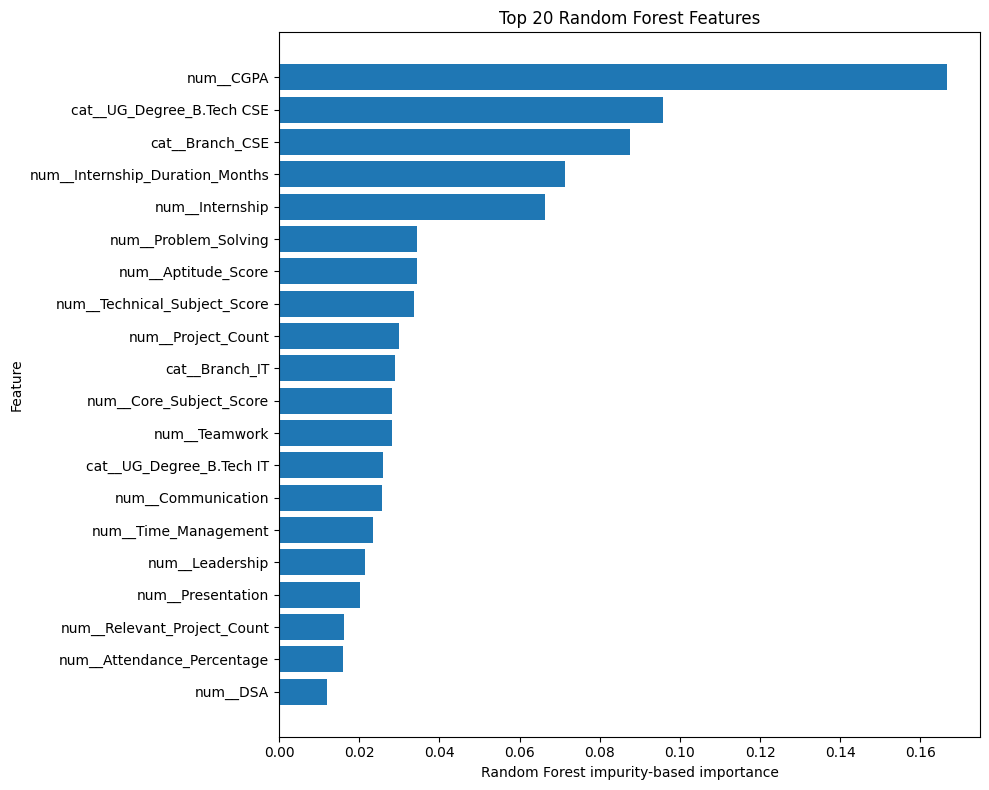


Saved: random_forest_feature_importance.csv


In [20]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt

# Load saved artifacts
model = joblib.load("/content/random_forest_model.joblib")
preprocessor = joblib.load("/content/preprocessor.joblib")

# Recover transformed feature names
feature_names = preprocessor.get_feature_names_out()
importances = model.feature_importances_

# Verify feature-name alignment
assert len(feature_names) == len(importances) == 169

# Create ranked importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

importance_df = importance_df.reset_index(drop=True)
importance_df.index += 1
importance_df.index.name = "Rank"

print("TOP 20 MOST IMPORTANT FEATURES")
display(importance_df.head(20).round(4))

# Save full results
importance_df.to_csv(
    "/content/random_forest_feature_importance.csv"
)

# Plot top 20
top20 = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Importance"])
plt.xlabel("Random Forest impurity-based importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")
plt.tight_layout()
plt.show()

print("\nSaved: random_forest_feature_importance.csv")


TOP 20 FEATURES — PERMUTATION IMPORTANCE


,Feature,Permutation_Importance,Std_Deviation
3,num__CGPA,0.0403,0.0110
151,cat__UG_Degree_B.Tech CSE,0.0282,0.0147
167,cat__Branch_IT,0.0262,0.0058
155,cat__UG_Degree_B.Tech IT,0.0237,0.0061
163,cat__Branch_CSE,0.0233,0.0121
137,num__Internship,0.0112,0.0033
138,num__Internship_Duration_Months,0.0083,0.0037
135,num__Project_Count,0.0073,0.0042
38,num__React,0.0023,0.0020
5,num__Backlogs,0.0015,0.0024


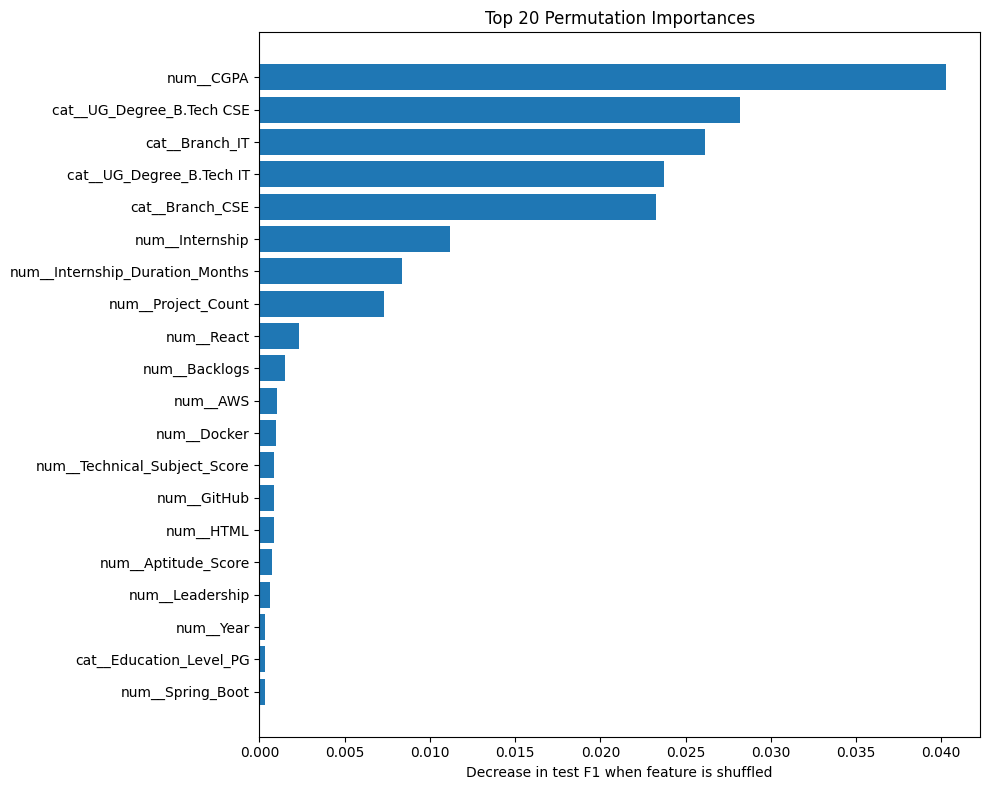

In [21]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

model = joblib.load("/content/random_forest_model.joblib")
preprocessor = joblib.load("/content/preprocessor.joblib")

feature_names = preprocessor.get_feature_names_out()

# X_test must contain the already-preprocessed test features.
X_test = np.load("/content/X_test_processed.npz")
y_test = pd.read_csv("/content/y_test.csv").squeeze().astype(int)

assert X_test.shape[1] == len(feature_names)

result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Permutation_Importance": result.importances_mean,
    "Std_Deviation": result.importances_std
}).sort_values("Permutation_Importance", ascending=False)

print("TOP 20 FEATURES — PERMUTATION IMPORTANCE")
display(importance_df.head(20).round(4))

importance_df.to_csv(
    "/content/random_forest_permutation_importance.csv",
    index=False
)

top20 = importance_df.head(20).sort_values("Permutation_Importance")

plt.figure(figsize=(10, 8))
plt.barh(
    top20["Feature"],
    top20["Permutation_Importance"]
)
plt.xlabel("Decrease in test F1 when feature is shuffled")
plt.title("Top 20 Permutation Importances")
plt.tight_layout()
plt.show()

In [22]:

import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Load the same train/test data for both models
# --------------------------------------------------
X_train = np.load("/content/X_train_processed.npz")
X_test = np.load("/content/X_test_processed.npz")

y_train = pd.read_csv("/content/y_train.csv").squeeze().astype(int)
y_test = pd.read_csv("/content/y_test.csv").squeeze().astype(int)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# --------------------------------------------------
# 2. Load the saved tuned Random Forest
# --------------------------------------------------
rf_model = joblib.load("/content/random_forest_model.joblib")

# --------------------------------------------------
# 3. Train Logistic Regression on the SAME split
# --------------------------------------------------
lr_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42
    )
)

lr_model.fit(X_train, y_train)

# --------------------------------------------------
# 4. Evaluate both models using the same metrics
# --------------------------------------------------
models = {
    "Logistic Regression": lr_model,
    "Tuned Random Forest": rf_model
}

results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy (%)": round(
            accuracy_score(y_train, train_pred) * 100, 2
        ),
        "Test Accuracy (%)": round(
            accuracy_score(y_test, test_pred) * 100, 2
        ),
        "Test Precision": round(
            precision_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test Recall": round(
            recall_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test F1": round(
            f1_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test ROC-AUC": round(
            roc_auc_score(y_test, test_prob), 4
        )
    })

comparison_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(comparison_df)

comparison_df.to_csv(
    "/content/final_model_comparison.csv",
    index=False
)

print("Saved: /content/final_model_comparison.csv")


Training data: (4000, 169)
Testing data: (1000, 169)

MODEL COMPARISON


,Model,Train Accuracy (%),Test Accuracy (%),Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,71.03,68.2,0.6159,0.6737,0.6435,0.7217
1,Tuned Random Forest,75.90,66.8,0.6004,0.6596,0.6286,0.7180


Saved: /content/final_model_comparison.csv


DATA VALIDATION
X_train: (4000, 169)
X_test : (1000, 169)
y_train: (4000,)
y_test : (1000,)

FINAL LOGISTIC REGRESSION RESULTS
model: Logistic Regression
train_accuracy: 0.7103
test_accuracy: 0.6820
test_precision: 0.6159
test_recall: 0.6737
test_f1: 0.6435
test_roc_auc: 0.7217
train_test_accuracy_gap: 0.0282
number_of_training_rows: 4000
number_of_test_rows: 1000
number_of_processed_features: 169

Classification Report:
                precision    recall  f1-score   support

Not Placed (0)       0.74      0.69      0.71       574
    Placed (1)       0.62      0.67      0.64       426

      accuracy                           0.68      1000
     macro avg       0.68      0.68      0.68      1000
  weighted avg       0.69      0.68      0.68      1000

Confusion Matrix:
[[395 179]
 [139 287]]


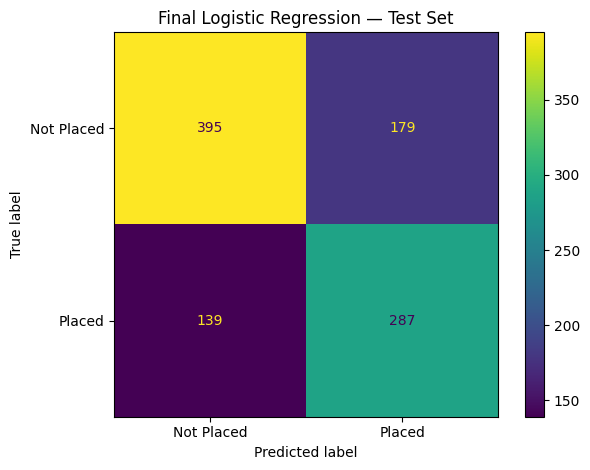


SAVED ARTIFACTS
/content/final_employability_model.joblib
/content/final_model_metrics.json
/content/final_model_classification_report.txt
/content/final_model_test_predictions.csv
/content/processed_feature_names.csv

MODEL FINALIZATION CELL COMPLETED.
Primary model saved as final_employability_model.joblib
Keep preprocessor.joblib alongside the model.


In [23]:

# ================================================================
# FINAL MODEL FINALIZATION — ENGINEERING EMPLOYABILITY PREDICTION
# Primary model: Logistic Regression
# Comparison: Tuned Random Forest
# ================================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------
# 1. Load existing processed train/test data
# ------------------------------------------------
BASE_PATH = "/content"

required_files = [
    "X_train_processed.npz",
    "X_test_processed.npz",
    "y_train.csv",
    "y_test.csv",
    "preprocessor.joblib"
]

missing_files = [
    f for f in required_files
    if not os.path.exists(os.path.join(BASE_PATH, f))
]

if missing_files:
    raise FileNotFoundError(
        "Upload or create these files in /content first:\n"
        + "\n".join(missing_files)
    )

X_train = np.load(f"{BASE_PATH}/X_train_processed.npz")
X_test = np.load(f"{BASE_PATH}/X_test_processed.npz")

y_train = pd.read_csv(
    f"{BASE_PATH}/y_train.csv"
).squeeze().astype(int)

y_test = pd.read_csv(
    f"{BASE_PATH}/y_test.csv"
).squeeze().astype(int)

preprocessor = joblib.load(
    f"{BASE_PATH}/preprocessor.joblib"
)

print("=" * 65)
print("DATA VALIDATION")
print("=" * 65)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_test.shape[1]
assert len(preprocessor.get_feature_names_out()) == X_train.shape[1]
assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})

# ------------------------------------------------
# 2. Train final Logistic Regression model
# ------------------------------------------------
final_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42
    )
)

final_model.fit(X_train, y_train)

# ------------------------------------------------
# 3. Evaluate the model
# ------------------------------------------------
train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)
test_prob = final_model.predict_proba(X_test)[:, 1]

metrics = {
    "model": "Logistic Regression",
    "train_accuracy": float(accuracy_score(y_train, train_pred)),
    "test_accuracy": float(accuracy_score(y_test, test_pred)),
    "test_precision": float(
        precision_score(y_test, test_pred, zero_division=0)
    ),
    "test_recall": float(
        recall_score(y_test, test_pred, zero_division=0)
    ),
    "test_f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "test_roc_auc": float(roc_auc_score(y_test, test_prob)),
    "train_test_accuracy_gap": float(
        accuracy_score(y_train, train_pred)
        - accuracy_score(y_test, test_pred)
    ),
    "number_of_training_rows": int(X_train.shape[0]),
    "number_of_test_rows": int(X_test.shape[0]),
    "number_of_processed_features": int(X_train.shape[1])
}

print("\n" + "=" * 65)
print("FINAL LOGISTIC REGRESSION RESULTS")
print("=" * 65)

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Not Placed (0)", "Placed (1)"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

# ------------------------------------------------
# 4. Plot the confusion matrix
# ------------------------------------------------
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=[0, 1],
    display_labels=["Not Placed", "Placed"],
    values_format="d"
)

plt.title("Final Logistic Regression — Test Set")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 5. Save the model and evaluation artifacts
# ------------------------------------------------
model_path = f"{BASE_PATH}/final_employability_model.joblib"
metrics_path = f"{BASE_PATH}/final_model_metrics.json"
report_path = f"{BASE_PATH}/final_model_classification_report.txt"
predictions_path = f"{BASE_PATH}/final_model_test_predictions.csv"
features_path = f"{BASE_PATH}/processed_feature_names.csv"

joblib.dump(final_model, model_path)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

with open(report_path, "w") as f:
    f.write(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Not Placed (0)", "Placed (1)"],
        zero_division=0
    ))

pd.DataFrame({
    "Actual_Status": np.asarray(y_test),
    "Predicted_Status": test_pred,
    "Model_Estimated_Placement_Score": test_prob
}).to_csv(predictions_path, index=False)

pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out()
}).to_csv(features_path, index=False)

print("\n" + "=" * 65)
print("SAVED ARTIFACTS")
print("=" * 65)
for path in [
    model_path,
    metrics_path,
    report_path,
    predictions_path,
    features_path
]:
    print(path)

print("\nMODEL FINALIZATION CELL COMPLETED.")
print("Primary model saved as final_employability_model.joblib")
print("Keep preprocessor.joblib alongside the model.")
